# Hälsostudie, del 1
Analys av deltagarnas ålder, vikt, längd, blodtryck, kolesterol, rökvanor och sjukdom.

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/health_study_dataset (1).csv")
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


## Beskrivande analys
medel, median, min och max för ålder, vikt, längd, systoliskt blodtryck och kolesterol.

In [37]:
kolumner = ["age",  "weight", "height", "systolic_bp", "cholesterol"]

df[kolumner].agg(["mean", "median", "min", "max"])

,age,weight,height,systolic_bp,cholesterol
mean,49.42625,73.413,171.84925,149.178625,4.92915
median,50.00000,73.200,171.35000,149.400000,4.97000
min,18.00000,33.700,144.40000,106.800000,2.50000
max,90.00000,114.400,200.40000,185.900000,7.88000


In [38]:
df.columns

Index(['id', 'age', 'sex', 'height', 'weight', 'systolic_bp', 'cholesterol',
       'smoker', 'disease'],
      dtype='str')

In [39]:
print(df["sex"].unique())
print(df["smoker"].unique())

<StringArray>
['F', 'M']
Length: 2, dtype: str
<StringArray>
['No', 'Yes']
Length: 2, dtype: str


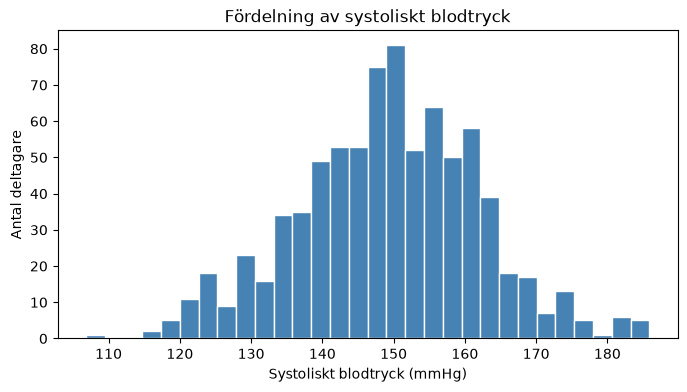

In [40]:
fig, ax = plt.subplots(figsize=(8,4))
ax.hist (df["systolic_bp"], bins=30, color="steelblue", edgecolor="white")
ax.set_title("Fördelning av systoliskt blodtryck")
ax.set_xlabel("Systoliskt blodtryck (mmHg)")
ax.set_ylabel("Antal deltagare")
plt.show()

Det systoliska blodtrycket ligger för de flesta deltagarna mellan cirka 140 och 160 mmHg, med flest värden runt 150 mmHg. Värdena sträcker sig från cirka 108 till 186 mmHg. Fördelningen är ungefär symmetrisk, vilket stämmer med att medel och median ligger nära varandra i min analys

## Vikt per kön

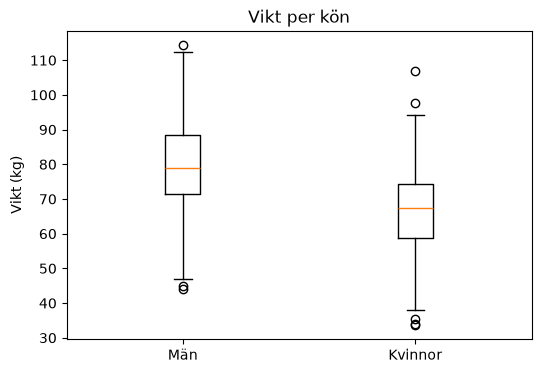

In [41]:
vikt_m = df[df["sex"] == "M"]["weight"]
vikt_f = df[df["sex"] == "F"]["weight"]

fig, ax = plt.subplots(figsize=(6,4))
ax.boxplot([vikt_m, vikt_f], tick_labels=["Män", "Kvinnor"])
ax.set_title("Vikt per kön")
ax.set_ylabel("Vikt (kg)")
plt.show()

Män väger i genomsnitt mer än kvinnor: medianen är cirka 79kg för män och cirka 67kg för kvinnor. Den mittersta hälften av männen väger mellan cirka 72 och 88kg, och av kvinnorna cirka 59 och 74kg. Grupperna överlappar delvis. Båda grupperna har nmågra extremvärde både låga och höga.

### Andel Rökare

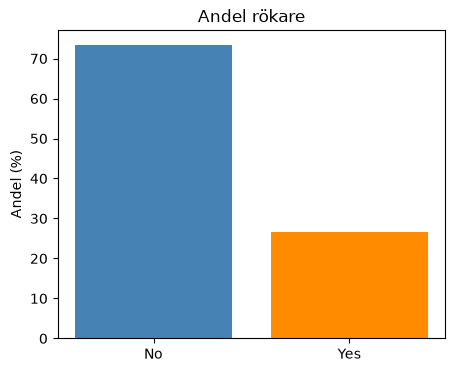

smoker
No     73.4
Yes    26.6
Name: proportion, dtype: float64

In [42]:
andel_rokare = df["smoker"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(5,4))
ax.bar(andel_rokare.index, andel_rokare.values, color=["steelblue", "darkorange"])
ax.set_title("Andel rökare")
ax.set_ylabel("Andel (%)")
plt.show()

andel_rokare.round(1)


Cirka 27% av deltagarna röker och cirka 73% röker inte, unefär var fjärde deltagare är alltså rökare

## Simulering av sjukdomsförekomst
Vi räknar ut andelen deltagare som har sjukdomen och simulerar sedan 1000 personer med samma sannolikhet för att se hur nära den simulerade andelen hamnar.

In [43]:
andel_sjuk = df["disease"].mean()

print("Andel med sjukdomen i datan:", round(andel_sjuk * 100, 1), "%")

Andel med sjukdomen i datan: 5.9 %


In [44]:
rng = np.random.default_rng(42)

simulerade = rng.binomial(n=1, p=andel_sjuk, size=1000)
sim_andel = simulerade.mean()

print("Simulerad andel:", round(sim_andel * 100, 1), "%")
print("Verklig andel:", round(andel_sjuk * 100,1), "%")
print("Skillnad:", round((sim_andel - andel_sjuk) * 100, 1), "procentenheter")

Simulerad andel: 5.4 %
Verklig andel: 5.9 %
Skillnad: -0.5 procentenheter


Den verkliga andelen med sjukdomen är 5,9%, och i simuleringen av 1000 personer blev andelen 5,4%, alltså 0,5 procentenheter lägre. Skillnaden beror på att simuleringen är slumpartad, den simulerade andelen är olika runt den verkliga, och med fler simulerade personer hamnar den i genomsnitt närmre.

## Konfidensintervall för systoliskt blodtryck
Räknar ut ett 95% konfidensintervall för medelvärdet med normalapproximation.

In [45]:
medel = df["systolic_bp"].mean()
se = df["systolic_bp"].std() / np.sqrt(len(df))

nedre = medel - 1.96 * se
ovre = medel + 1.96 * se

print("Medelvärde:", round(medel, 1), "mmHg")
print("95 % konfidensintervall:", round(nedre,1), "till", round(ovre,1), "mmHg")

Medelvärde: 149.2 mmHg
95 % konfidensintervall: 148.3 till 150.1 mmHg


medelvärdet för det systoliska blodtrycket är 149,2 mmHg. Med normalapproximation blir 95% konfidensintervallet 148,3 till 150,1 mmHg. Vi kan alltså vara 95% säkra att på detr verkliga medelvärdet i hela populationen ligger inom det intervallet.

In [46]:
rng = np.random.default_rng(42)

boot_medel = []
for i in range(1000):
    stickprov = rng.choice(df["systolic_bp"], size=len(df))
    boot_medel.append(stickprov.mean())

nedre_boot = np.percentile(boot_medel, 2.5)
ovre_boot = np.percentile(boot_medel, 97.5)

print("Bootstrap 95 % KI:", round(nedre_boot, 1), "till", round(ovre_boot, 1), "mmHg")

Bootstrap 95 % KI: 148.3 till 150.0 mmHg


med bootstrapen blev intervallet 148,3 till 150,0 mmHg, nästan exakt samma som med normalapproximation. Normalapproximationen förutsätter att medelvärdet är ungefär normalfördelat, vilket gäller när stickprovet är stort. Bootstrapå kräver inget sådant antagande, utan skrattar nästan osäkerheten direkt ur data lol. Att båda metoderna ger nästan samma intervall stärker min slutsats.

## Hypotesprövning: rökare och blodtryck
Ska testa om rökare har högre medel-blodtryck än ickerökare

- Nollhyptoes(H0): rökare och icke-rökare med samma medel-blodtryck.
- Mothypotes (H1): rökare har högre medel-blodtryck än icke-rökare.

Använder mig av ett t-test och signifikansnivån 0,05.

In [ ]:
rokare = df[df["smoker"] == "Yes"]["systolic_bp"]
icke_rokare = df[df["smoker"] == "No"]["systolic_bp"]

print("Rökare:", round(rokare.mean(), 1), "mmHg")
print("Icke-rökare:", round(icke_rokare.mean(), 1), "mmHg")
print("Skillnad:", round(rokare.mean() - icke_rokare.mean(), 1), "mmHg")

Rökare: 149.5 mmHg
Icke-rökare: 149.1 mmHg
Skillnad: 0.5 mmHg


In [ ]:
from scipy import stats

resultat = stats.ttest_ind(rokare, icke_rokare, equal_var=False, alternative="greater")

print("p-värde:", round(resultat.pvalue, 4))

p-värde: 0.3264


### Resultat
Rökare har i genomsnitt 149,5 mmHg i systoliskt blodtryck och icke-rökare 149,1 mmHg, en skillnad på cirka 0,5 mmHg. T-testet gav p = 0,33

Eftersom p-värdet är större än 0,05 kan vi inte förkasta nollhypotesen. Datan har alltså inget stöd för att rökare har högre medel-blodtryck än icke-rökare. En så liten skillnad kan enkelt nog uppstå av rena slumpen egentligen.

Det betyder inte att det bevisats att rökningen saknar betydelse för blodtrycket, utan att skillnaden inte sysn i den här datan helt enkelt.

### Power - hur säkert är testet?
Power är sannolikheten att testet hittar en skillnad när den verkligen finns. Så jag simulerar data där rökare har ett högre medel-blodtryck än icke-rökare, med samma gruppstorlekjar och spridning som i min data. Kör t-testet 1000 gånger och räknar hur ofta det blir signifikant (p < 0,05)

In [ ]:
rng = np.random.default_rng(42)

n_rok = len(rokare)
n_icke = len(icke_rokare)
std = df["systolic_bp"].std()
medel = icke_rokare.mean()

skillnad = 5
signifikant = 0

for i in range(1000):
    sim_icke = rng.normal(medel, std, n_icke)
    sim_rok = rng.normal(medel + skillnad, std, n_rok)
    p = stats.ttest_ind(sim_rok, sim_icke, equal_var=False, alternative="greater").pvalue
    if p < 0.05:
        signifikant += 1

power = signifikant / 1000
print("Verklig skillnad i simuleringen:", skillnad, "mmHg")
print("Power:", round(power * 100, 1), "%")

Verklig skillnad i simuleringen: 5 mmHg
Power: 100.0 %


In [ ]:
for skillnad in [0.5, 1, 2, 3, 5]:
    signifikant = 0
    for i in range(1000):
        sim_icke = rng.normal(medel, std, n_icke)
        sim_rok = rng.normal(medel + skillnad, std, n_rok)
        p = stats.ttest_ind(sim_rok, sim_icke, equal_var=False, alternative="greater").pvalue
        if p < 0.05:
            signifikant += 1

    print("Skillnad", skillnad, "mmHg: power", round(signifikant / 1000 * 100, 1), "%")

Skillnad 0.5 mmHg: power 12.7 %
Skillnad 1 mmHg: power 26.7 %
Skillnad 2 mmHg: power 61.2 %
Skillnad 3 mmHg: power 90.0 %
Skillnad 5 mmHg: power 100.0 %


### Tolkning av pwr
Testet hittade stora skillnader nästan alltid, vid 3mmHg är power 90% och vid 5mmHg 100%. Små skillnader dock vilket är svåra att upptäcka. Vid 0,5mmHg, nästan skillnaden jag såg mellan rökare och icke-rökare, hittade testet skillnaden bara i cirka 13% av fallen.
Om rökare skulle ha något högre blodtryck är skillnaden i min data så liten att  testet sällan kan skilja den från slumpen. Fatt kunna säkerhetsställa skillnaden på 0,5mmHg hade studien behövt fler deltagare helt enkelt.

## Metodval
**Beskrivande analys och grafer.** Jag räknade ut medel, median, min och maxmed pandas [1]. Jag valde ett histogram för att se hur blodtrycket fördelar sig [2], ett lådagram för att jämföra vikten mellan män och kvinnor [3] och ett stapeldiagram för att visa hur stor andel som röker [4].
**Simulering.** Jag simulerade sjukdomen med en binomialfördelning [6], eftersom varje person antingen har sjukdomen (1) eller inte (0). Jag använde ett fast seed [5] så att jag får samma resultat varje gång jag kör koden. **Konfidensintervall.** Jag räknade ut konfidensintervallet på två sätt. Normalapproximationen bygger på standardfelet [9] och förutsätter att medelvärdet är ungefär normalfördelat, vilket stämmer när man har många deltagare. Bootstrap [7][8] behöver inte det antagandet, eftersom den drar nya stickprov direkt ur datan. Båda metoderna gav nästan samma intervall, så jag litar mer på resultatet.
**Hypotesprövning.** Jag valde ett t-test för två oberoende grupper eftersom jag jämför medelvärdet i två separata grupper, rökare och icke-rökare [10]. Jag använde Welchs variant (equal_var=False) eftersom den inte kräver att grupperna har samma spridning [11]. Testet är ensidigt (alternative="greater") eftersom hypotesen bara handlar om att rökare har högre blodtryck.
**Power.** Med power-simuleringen ville jag se hur stor skillnad testet kan hitta med min datamängd [12]. Den förklarar varför den lilla skillnaden mellan rökare och icke-rökare inte blev signifikant.

## Referenser
1. pandas, DataFrame.agg. https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.agg.html
2. matplotlib, Axes.hist. https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.hist.html
3. matplotlib, Axes.boxplot. https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.boxplot.html
4. matplotlib, Axes.bar. https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.bar.html
5. NumPy, numpy.random.default_rng. https://numpy.org/doc/stable/reference/random/generator.html
6. NumPy, Generator.binomial. https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.binomial.html
7. NumPy, Generator.choice. https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html
8. NumPy, numpy.percentile. https://numpy.org/doc/stable/reference/generated/numpy.percentile.html
9. Statistics by Jim, Standard Error of the Mean. https://statisticsbyjim.com/hypothesis-testing/standard-error-mean/
10. SciPy, scipy.stats.ttest_ind. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html
11. Wikipedia, Welch's t-test. https://en.wikipedia.org/wiki/Welch%27s_t-test
12. Statistics by Jim, Sample Size and Power Analysis. https://statisticsbyjim.com/hypothesis-testing/sample-size-power-analysis/